In [1]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_cells_dev/figures/l5_ET_tuning/'
# import os
# os.mkdir(figpth)

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils')
from cell_builder_utils import l5_params, _get_dends, _get_pyr_soma, Cell
from l5_mechs_utils import Mechs, Ih_condu_hay, linear_gbar
from l5_plot_utils import fig_conductances, _hammfilt, get_colormap, get_l5pyr
from functools import partial
import os
from scipy.signal import find_peaks
from scipy import signal
from scipy.optimize import curve_fit
plt.rcParams['svg.fonttype'] = 'none'

# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.py:132: SyntaxWarning: invalid escape sequence '\m'
  ax[0,0].set_xlabel('distance to soma ($\mu m$)')
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.py:136: SyntaxWarning: invalid escape sequence '\m'
  ax[0,1].set_xlabel('distance to soma ($\mu m$)')
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.py:141: SyntaxWarning: invalid escape sequence '\m'
  ax[0,2].set_xlabel('distance to soma ($\mu m$)')
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.py:524: SyntaxWarning: invalid escape sequence '\m'
  ax[0].set_xlabel('distance from soma ($\mu m$)')
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.py:530: SyntaxWarning: invalid escape sequence '\c'
  ax[1].set_ylabel('membr. pot. integral (mV$\cdot$s)')
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.

In [2]:
model_params = {'soma': {'NaTs2_t': 20_400e-4/2*1.5,
                                'SKv3_1': 6_930e-4/2,
                                'Nap_Et2': 17.2e-4/2*0.11,
                                'Ca_HVA': 9.92e-04/2,
                                'Ca_LVAst': 34.3e-4/2,
                                'SK_E2': 441e-4*15,                      # increase this one to get burst followed by regular firing
                                'Ih': 1e-4/2,
                                'Im': 1e-4,
                                'K_Pst': 22.3e-4/2,#*0.1,
                                'K_Tst': 812e-4/2,#*0.1,
                                'pas': {'g': .338e-4/2/2,
                                          'e': -90}},
                        'basal': {'NaTs2_t': partial(linear_gbar,0.0102,0,255),
                                'SKv3_1': partial(linear_gbar,0,0.0001305,255),
                                  'Ih': 5.14e-5/4*2,
                                  'pas': {'g': 1.75e-5/2*3,
                                          'e': -90}},
                        'dend': {'NaTa_t': 0.0213/2,
                                'SKv3_1': 0.000261/2*2,
                                'Ca_HVA': partial(linear_gbar, 2.78e-5/2, 2.78e-5/2*12.0, 1500, hotzone=[1500, 1700], hotzone_factor=4.5),
                                'Ca_LVAst': partial(linear_gbar, 93.5e-6/2, 93.5e-6/2*2.25, 1500, hotzone=[1500, 1700], hotzone_factor=2.25),
                                'SK_E2': 0.0012/2*6,#*2,#*1.6,
                                'Ih': partial(Ih_condu_hay, 1e-4/2*1.2),   
                                'Im': 0.0000675/2,
                                'K_Pst': 0,
                                'K_Tst': 0,
                                'pas': {'g': 0.0000589/1.5,
                                          'e': -85}}}

# Ra = 200
# if Ra = 200
# model_params = {'soma': {'NaTs2_t': 20_400e-4/2*1.5,
#                                 'SKv3_1': 6_930e-4/2,
#                                 'Nap_Et2': 17.2e-4/2,
#                                 'Ca_HVA': 9.92e-04/2,
#                                 'Ca_LVAst': 34.3e-4/2,
#                                 'SK_E2': 441e-4*10,                      # increase this one to get burst followed by regular firing
#                                 'Ih': 1e-4/2/2,
#                                 'Im': 1e-4,
#                                 'K_Pst': 22.3e-4/2,#*0.1,
#                                 'K_Tst': 812e-4/2,#*0.1,
#                                 'pas': {'g': 1/37000, #.338e-4/2,
#                                           'e': -90}},
#                         'basal': {'NaTs2_t': partial(linear_gbar,20_400e-4/2*0.01,0,255),
#                                 'SKv3_1': partial(linear_gbar,0,0.000261/2,255),
#                                   'Ih': 5.14e-5/4*2,
#                                   'pas': {'g': 1/37000, #1.75e-5/2*2,
#                                           'e': -90}},
#                         'dend': {'NaTa_t': 0.0213/2,
#                                 'SKv3_1': 0.000261/2,
#                                 'Ca_HVA': partial(linear_gbar, 2.78e-5/2*1., 2.78e-5/2*10.5, 1500, hotzone=[1500, 1700], hotzone_factor=3.0),
#                                 'Ca_LVAst': partial(linear_gbar, 93.5e-6/2, 93.5e-6/2*2.25, 1500, hotzone=[1500, 1700], hotzone_factor=2.5),
#                                 'SK_E2': 0.0012/2*6,#*2,#*1.6,
#                                 'Ih': partial(Ih_condu_hay, 1e-4/2*1.2),   
#                                 'Im': 0.0000675/2,
#                                 'K_Pst': 0,
#                                 'K_Tst': 0,
#                                 'pas': {'g': 0.0000589/2,
#                                           'e': -85}}}






Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.py:132: SyntaxWarning: invalid escape sequence '\m'
  ax[0,0].set_xlabel('distance to soma ($\mu m$)')
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.py:136: SyntaxWarning: invalid escape sequence '\m'
  ax[0,1].set_xlabel('distance to soma ($\mu m$)')
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.py:141: SyntaxWarning: invalid escape sequence '\m'
  ax[0,2].set_xlabel('distance to soma ($\mu m$)')
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.py:524: SyntaxWarning: invalid escape sequence '\m'
  ax[0].set_xlabel('distance from soma ($\mu m$)')
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.py:530: SyntaxWarning: invalid escape sequence '\c'
  ax[1].set_ylabel('membr. pot. integral (mV$\cdot$s)')
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils/l5_plot_utils.

TypeError: 'Cell' object is not subscriptable

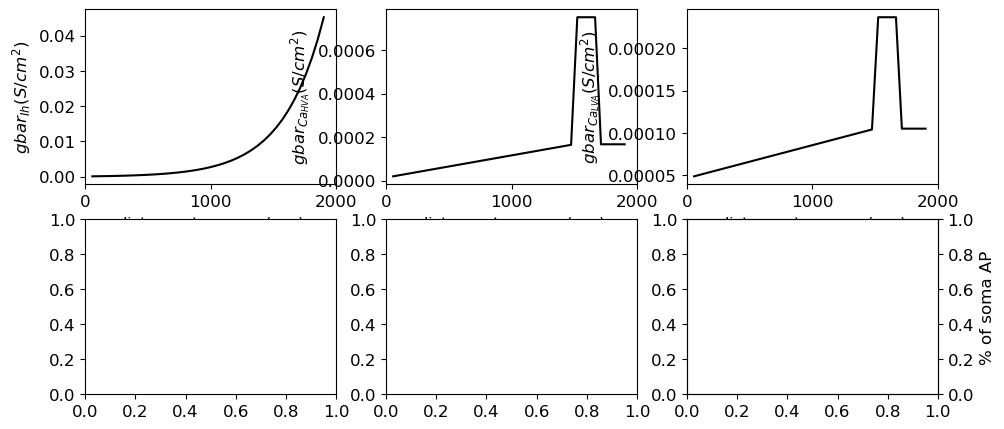

In [3]:
# get paramaters
section_params, end_pts, cell_tree = l5_params()

# build sections
section_names = list(end_pts.keys())

v_init = {'soma': -70.62820902070445,
            'basal_1': -70.68833400623593,
            'basal_2': -70.77775514983897,
            'basal_3': -70.77775514983897,
            'apical_oblique': -70.59471467725159,
            'apical_trunk': -70.5815879670308,
            'apical_1': -69.62883464685193,
            'apical_2': -65.7496819357426,
            'apical_tuft': -61.28751781712565}

sections = _get_dends(section_params, 'L5Pyr', section_names, end_pts, v_init=v_init)
sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr', end_pts['soma'], v_init=v_init['soma'])

mech_class = Mechs(pth_mod)


hotzone = [1500, 1700]
l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()

l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)


# Show conductances

fig, amp = fig_conductances(l5pyr)

fig.savefig(os.path.join(figpth, 'conductances.png'))
fig.savefig(os.path.join(figpth, 'conductances.pdf'))


In [4]:
l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()

l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)
distance = []
h.distance(sec = l5pyr._nrn_sections['soma'])
section_names = ['soma', 'basal_1','basal_2', 'basal_3', 'apical_oblique', 'apical_trunk','apical_1', 'apical_2', 'apical_tuft']
sec_seg = []

v_s = []
for s, section in enumerate(section_names):
    v_s.append(h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v))

t = h.Vector().record(h._ref_t)
h.celsius = 37
h.finitialize()
h.continuerun(100 * ms)

for s, section in enumerate(section_names):
    v = v_s[s].as_numpy()
    #print(f"'{section}': {v[-1]},")

NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas


NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas
NaTs2_t
SKv3_1
Ih
pas


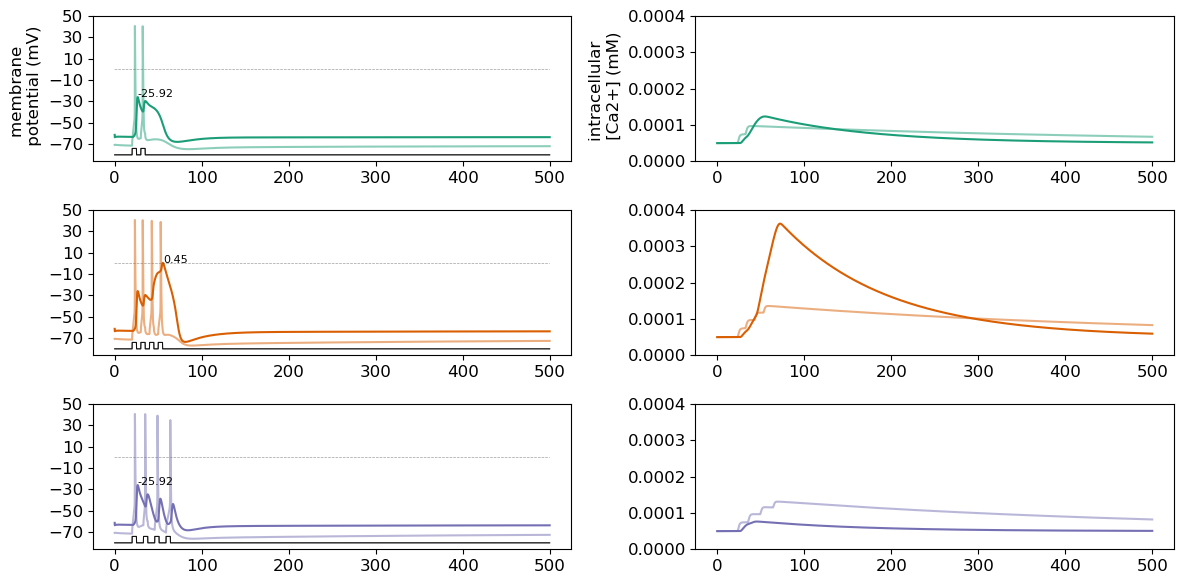

In [5]:
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
fig, ax = plt.subplots(3, 2, figsize=(12,6))
h('forall delete_section()')
nums_pulse = [2, 4, 4]
time_diff = [10, 10, 13]
l_stim = 500

section_names = ['apical_tuft', 'soma']

voltg = [None]*len(section_names)
ca = [None]*len(section_names)

for n, num_pulse in enumerate(nums_pulse):
    del l5pyr
    l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l5pyr.build()

    l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)

    stim = [None]*num_pulse
    t = h.Vector().record(h._ref_t)
    for i in range(num_pulse):
        stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
        stim[i].delay = 20+(time_diff[n]*i)
        stim[i].dur = 5
        stim[i].amp = 3

    voltg[1] = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
    ca[1] = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_cai)

    voltg[0] = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.1)._ref_v)
    ca[0] = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.1)._ref_cai)

    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    clamp_current = np.zeros_like(t.as_numpy())
    for i in range(num_pulse):
        clamp_current[(t.as_numpy() > stim[i].delay) & (t.as_numpy() < stim[i].delay+stim[i].dur)] = stim[i].amp

    for s, section in enumerate(section_names):
        ax[n, 0].plot(t.as_numpy(), np.zeros_like(t.as_numpy()), color='black', alpha=0.2, linewidth=0.5, linestyle='--')
        ax[n, 0].plot(t, voltg[s], color=cols[n], alpha=1/(s+1))
        ax[n, 0].plot(t.as_numpy(), clamp_current*2-80, color='black', alpha=0.75, linewidth=0.75)


        if section == 'apical_tuft':
            v_max = np.max(voltg[s].as_numpy())
            t_max = np.argmax(voltg[s].as_numpy())
            ax[n, 0].text(t[t_max], v_max, f'{v_max:.2f}', fontsize=8)
            
            ax[n, 1].plot(t, ca[s], label=f'{num_pulse} pulses, {time_diff[n]} ms apart', color=cols[n], alpha=1/(s+1))
            
        else:
            ax[n, 1].plot(t, ca[s], color=cols[n], alpha=1/(s+1))
    
    #ax[n, 0].set_xlim([0, 120])
    ax[n, 1].set_yticks(np.arange(0, 0.0005, 0.0001))
    #ax[n, 1].set_xlim([0, 120])
    ax[n, 0].set_yticks(np.arange(-70, 70, 20))

    # for i in range(2):
    #     ax[n, i].spines['top'].set_visible(False)
    #     ax[n, i].spines['right'].set_visible(False)
    #     ax[n, i].spines['bottom'].set_bounds(0, 10)
    #     ax[n, i].set_yticks([])
    #     ax[n, i].set_xticks([])
    #     ax[n, i].spines['bottom'].set_linewidth(1.25)
    #     ax[n, i].spines['left'].set_linewidth(1.25)
    
    # ax[n, 0].spines['left'].set_bounds(-85, -35)
    # ax[n, 1].spines['left'].set_bounds(0, 0.0001)

ax[0, 0].set_ylabel('membrane \n potential (mV)')
ax[0, 1].set_ylabel('intracellular \n [Ca2+] (mM)')
fig.tight_layout()
# fig.savefig(figpth+'soma_vs_apical_critfreq_blockca.png')
# fig.savefig(figpth+f'soma_vs_apical_critfreq_blockca.svg', format='svg')

In [ ]:
fig, ax = plt.subplots(4, 2, figsize=(12,8))

h('forall delete_section()')
nums_pulse = [1, 1, 2, 1]
pulse_sect = [['soma'], ['apical_tuft'],['soma', 'apical_tuft'], ['apical_tuft']]
ampl = [[3], [0.5], [3, 0.5], [2], ]
time_diff = [[0], [0], [0, 5], [0]]
l_stim = 150

section_names = ['apical_tuft', 'soma']

voltg = [None]*len(section_names)
ca = [None]*len(section_names)

for n, num_pulse in enumerate(nums_pulse):
    del l5pyr
    l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l5pyr.build()

    l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)

    stim = [None]*num_pulse
    t = h.Vector().record(h._ref_t)
    
    for i in range(num_pulse):
        stim[i] = h.IClamp(l5pyr._nrn_sections[pulse_sect[n][i]](0.5))
        stim[i].delay = 20+(time_diff[n][i])
        stim[i].dur = 5
        stim[i].amp = ampl[n][i]


    for s, section in enumerate(section_names):
        voltg[s] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v)
        ca[s] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_cai)


    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    clamp_current = np.zeros((num_pulse, len(t.as_numpy())))
    for i in range(num_pulse):
        clamp_current[i][(t.as_numpy() > stim[i].delay) & (t.as_numpy() < stim[i].delay+stim[i].dur)] = stim[i].amp*3

    for s, section in enumerate(section_names):
        for i in range(num_pulse):
            if pulse_sect[n][i] == 'soma':
                col = 'black'
                c = clamp_current[i]*2-95
            else:
                col = 'red'
                c = -clamp_current[i]*2-73
            ax[n, 0].plot(t.as_numpy(), c, color=col, alpha=0.75, linewidth=0.75)


        for s, section in enumerate(section_names):
            ax[n, 0].plot(t.as_numpy(), np.zeros_like(t.as_numpy()), color='black', alpha=0.2, linewidth=0.5, linestyle='--')
            ax[n, 0].plot(t, voltg[s], color=cols[n], alpha=1/(s+1))

            if section == 'apical_tuft':
                v_max = np.max(voltg[s].as_numpy())
                t_max = np.argmax(voltg[s].as_numpy())
                ax[n, 0].text(t[t_max], v_max, f'{v_max:.2f}', fontsize=8)
                
                ax[n, 1].plot(t, ca[s], label=f'{num_pulse} pulses, {time_diff[n]} ms apart', color=cols[n], alpha=1/(s+1))
                
            else:
                ax[n, 1].plot(t, ca[s], color=cols[n], alpha=1/(s+1))
        
        ax[n, 0].set_xlim([0, 120])
        ax[n, 1].set_yticks(np.arange(0, 0.0005, 0.0001))
        ax[n, 1].set_xlim([0, 120])
        ax[n, 0].set_yticks(np.arange(-70, 70, 20))

        # for i in range(2):
        #     ax[n, i].spines['top'].set_visible(False)
        #     ax[n, i].spines['right'].set_visible(False)
        #     ax[n, i].spines['bottom'].set_bounds(0, 10)
        #     ax[n, i].set_yticks([])
        #     ax[n, i].set_xticks([])
        #     ax[n, i].spines['bottom'].set_linewidth(1.25)
        #     ax[n, i].spines['left'].set_linewidth(1.25)
        
        # ax[n, 0].spines['left'].set_bounds(-85, -35)
        # ax[n, 1].spines['left'].set_bounds(0, 0.0001)
ax[0,0].set_ylabel('membrane \n potential (mV)')
ax[0,1].set_ylabel('intracellular \n [Ca2+] (mM)')

fig.tight_layout()
fig.savefig(figpth+'soma_vs_apical_coincidence_noca.png')
fig.savefig(figpth+f'soma_vs_apical_coincidence_noca.svg')

In [ ]:
del l5pyr
h('forall delete_section()')
l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)

l5pyr.build(sec_name_apical='apical_tuft')

l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)

num_pulse = 4

section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
stim = [None]*num_pulse
t = h.Vector().record(h._ref_t)
for i in range(num_pulse):
    stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 20+(8*i)  
    stim[i].dur = 5
    stim[i].amp = 3

rec_ca = []
rec_mV = []
distance = []
h.distance(sec = l5pyr._nrn_sections['soma'])
for section in section_names:
    for i, seg in enumerate(l5pyr._nrn_sections[section]):
        rec_ca.append(h.Vector().record(l5pyr._nrn_sections[section](seg.x)._ref_cai))
        rec_mV.append(h.Vector().record(l5pyr._nrn_sections[section](seg.x)._ref_v))
        distance.append(h.distance(seg.x, sec=seg.sec))

t = h.Vector().record(h._ref_t)
h.celsius = 37
h.finitialize()
h.continuerun(100 * ms)

sfreq = 1000/h.dt
winsz = int(20*sfreq/1000)  # 5 ms window

rec_ca_array = np.zeros((len(rec_ca), len(rec_ca[0].as_numpy())))
rec_mV_array = np.zeros((len(rec_mV), len(rec_ca[0].as_numpy())))
c = 0
for section in section_names:
    for i, seg in enumerate(l5pyr._nrn_sections[section]):
        rec_ca_array[c, :] = rec_ca[c].as_numpy()
        rec_mV_array[c, :] = rec_mV[c].as_numpy()
        c += 1

fig, ax = plt.subplots(1,3, figsize=(12, 3), constrained_layout=True)
im1 = ax[0].pcolormesh(t.as_numpy(), distance, rec_mV_array, cmap='RdBu_r', vmin=-70, rasterized=True)
cb1 = plt.colorbar(im1, ax=ax[0], label='membrane potential (mV)')
ax[0].set_ylabel('distance from soma ($\mu m$)')
ax[0].set_xticks(np.arange(0, 101, 50))
im2 = ax[1].pcolormesh(t.as_numpy(), distance, rec_ca_array, cmap='gist_gray', vmin=0, vmax=0.0003, rasterized=True)
cb2 = plt.colorbar(im2, ax=ax[1], label='intracell. calcium (mM)')
ax[1].set_xlabel('time (ms)')
ax[1].set_xticks(np.arange(0, 101, 50))
ax[2].plot(t.as_numpy(), _hammfilt(l5pyr.dipole.as_numpy()* 1e-6, winsz), color='k')
ax[2].set_ylabel('dipole moment (nA$\cdot$m)')
ax[2].spines['top'].set_visible(False)
ax[2].spines['right'].set_visible(False)

for a in ax:
    a.set_xlim([0, 100])
    a.set_xlabel('time (ms)')

    
fig.savefig(figpth+'membr_pot_calcium_dipole_allsegs.png')
fig.savefig(figpth+f'membr_pot_calcium_dipole_allsegs.pdf')

In [ ]:
stim_dur = 50
time_diff = np.linspace(17, 7, 10)
freqs = np.zeros_like(time_diff)
apcl_max = np.zeros_like(time_diff)
apcl_integr = np.zeros_like(time_diff)
for n, td in enumerate(time_diff):
    del l5pyr
    h('forall delete_section()')

    l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l5pyr.build()

    l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)

    t = h.Vector().record(h._ref_t)
    num_pulse = 4
    stim = [None]*4
    t = h.Vector().record(h._ref_t)
    for i in range(num_pulse):
        stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
        stim[i].delay = 20+(td*i)  
        stim[i].dur = 5
        stim[i].amp = 3

    v_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
    v_apcl = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.1)._ref_v)
    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    freqs[n] = 1000/td
    v_apcl = v_apcl.as_numpy()
    pk = find_peaks(v_apcl, prominence=15)

    apcl_max[n] = np.max(v_apcl)
    apcl_integr[n] = np.sum(v_apcl-v_apcl[pk[1]['left_bases'][0]])*h.dt*0.001

In [ ]:
threshold = []
for s, section in enumerate(section_names):
    for i, seg in enumerate(l5pyr._nrn_sections[section]):
        tuft_mp = -70 # initialize to a value below threshold
        amp = 0.1 # starting value for stimulation amplitude

        
        while tuft_mp < 0: # has MP reached critical threshold?
            del l5pyr

            l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
            l5pyr.build()
            l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)

            stim = h.IClamp(l5pyr._nrn_sections[section](seg.x))
            stim.delay = 20 
            stim.dur = 100
            stim.amp = amp

            v = h.Vector().record(l5pyr._nrn_sections[section](seg.x)._ref_v)
            ca = h.Vector().record(l5pyr._nrn_sections[section](seg.x)._ref_cai)
            t = h.Vector().record(h._ref_t)

            h.celsius = 37
            h.finitialize()
            h.continuerun(100 * ms)

            tuft_mp =np.max(v.as_numpy())
            amp += 0.2


        threshold.append(amp)

In [ ]:
# Beaulieau-Laroche - does voltage sag increase as function of distance from soma?
amp = -.5
sag_ratio = []

section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
for s, section in enumerate(section_names):

    for i, seg in enumerate(l5pyr._nrn_sections[section]):
        del l5pyr
        l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
        l5pyr.build()
        l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)

        stim = h.IClamp(l5pyr._nrn_sections[section](seg.x))
        stim.delay = 20
        stim.dur = 150
        stim.amp = amp
        clamp_current = h.Vector().record(stim._ref_i)

        t = h.Vector().record(h._ref_t)
        soma_voltg = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v)

        h.celsius = 37
        h.finitialize()
        h.continuerun(250 * ms)

        steady_idx = np.argmin(np.abs(t-150))
        soma_v = soma_voltg.as_numpy()

        pk = np.min(soma_v)
            

        steady_state = soma_v[steady_idx]

        # Sag ratio - see Beaulieu-Learoche

        sag_ratio.append((pk-steady_state)/pk)

In [ ]:
# input resistance
rec_ca = []
rec_mV = []
inp_res = []


for s, section in enumerate(section_names):
    for i, seg in enumerate(l5pyr._nrn_sections[section]):
        tuft_mp = -70 # initialize to a value below threshold
        amp = 0.1 # starting value for stimulation amplitude
        del l5pyr 
        l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
        l5pyr.build()
        l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)

        impedance = h.Impedance()
        h.celsius = 37
        h.finitialize()
        impedance.loc(seg.x, sec=l5pyr._nrn_sections[section])
        impedance.compute(0)
        inp_res.append(impedance.input(l5pyr._nrn_sections[section](seg.x)))


In [ ]:
fig, ax = plt.subplots(1,4, figsize=(8, 6), constrained_layout=True)
ax[0,0].plot(distance, threshold, 'o', color='k')
ax[0,0].set_ylabel('threshold (nA)')
ax[0,0].set_xlabel('distance from soma ($\mu m$)')

ax[0,1].plot(freqs, apcl_integr, 'o', color='black', markersize=7)
ax[0,1].set_xlim([np.min(freqs)-1, np.max(freqs)+1])
ax[0,1].set_ylabel('membr. pot. integral (mV$\cdot$s)')
ax[0,1].set_xlabel('input frequency (Hz)')
ax[1,0].plot(distance, sag_ratio, 'o', color='k')

ax[1,0].set_ylabel('sag ratio')
ax[1,0].set_xlabel('distance from soma ($\mu m$)')

ax[1,1].plot(distance, inp_res, 'o', color='k')
ax[1,1].set_xlabel('distance from soma ($\mu m$)')
ax[1,1].set_ylabel('input resistance (M$\Omega$)')
fig.savefig(figpth+'l5_et_ephys_props.png')
fig.savefig(figpth+'l5_et_ephys_props.pdf')

In [ ]:
from matplotlib import colormaps



def attenuation_from_section(section_names, ref_sect, amp, stim_dur, ax):

    l5pyr = get_l5pyr()

    amp_ref = []
    amp_dend = []
    steady_ref = []
    steady_dend = []

    distance = []
    i = 0

    stim = h.IClamp(l5pyr._nrn_sections[ref_sect](0.5))
    stim.delay = 20
    stim.dur = stim_dur
    stim.amp = amp

    t = h.Vector().record(h._ref_t)
    ref_voltg = h.Vector().record(l5pyr._nrn_sections[ref_sect](0.5)._ref_v)
    
    for s, section in enumerate(section_names):
        for sg, seg in enumerate(l5pyr._nrn_sections[section]):
            
            dend_voltg = h.Vector().record(l5pyr._nrn_sections[section](seg.x)._ref_v)
            
            distance.append(h.distance(l5pyr._nrn_sections[ref_sect](0.9), l5pyr._nrn_sections[section](seg.x)))
            
            h.celsius = 37
            h.finitialize()
            h.continuerun(250 * ms)
            

            if amp > 0:
                amp_ref.append(np.max(ref_voltg.as_numpy()) - np.min(ref_voltg.as_numpy()))
                amp_dend.append(np.max(dend_voltg.as_numpy()) - np.min(dend_voltg.as_numpy()))
                
            if amp < 0:

                amp_ref.append(np.min(ref_voltg.as_numpy()))
                amp_dend.append(np.min(dend_voltg.as_numpy()))
                # find steady state
                steady_idx = np.argmin(np.abs(t.as_numpy()-(stim.delay+stim.dur-10)))
                end_idx = np.argmin(np.abs(t.as_numpy()-(stim.delay+stim.dur)))
                steady_ref.append(np.mean(ref_voltg.as_numpy()[steady_idx:end_idx]))
                steady_dend.append(np.mean(dend_voltg.as_numpy()[steady_idx:end_idx]))

            
            ax.plot(t, dend_voltg, color=cols_dist[i])
            i += 1
    ax.plot(t, ref_voltg, color=cols_dist[0]) 
    cb = plt.colorbar(im, ax=ax, orientation='horizontal', label=f'distance from {ref_sect} ($\mu m$)', shrink=0.5)
    ax.set_ylabel('membrane potential (mV)')
    ax.set_xlabel('time (ms)')
    # calculate attenuation
    atten = np.array(amp_dend) / np.array(amp_ref) * 100

    if amp < 0:
        atten_steady = np.array(steady_dend) / np.array(steady_ref) * 100
        return atten, atten_steady, distance

    else:
        return atten, distance






In [ ]:
def exp_decay(x, lambda_val, A):
    return A * np.exp(-x / lambda_val)

In [ ]:
# soma to dendrite attenuation
cmap = colormaps['inferno']
cols_dist = cmap.colors[0:len(cmap.colors):6]
im = get_colormap(cmap_name='inferno')

section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
ref_sect = 'soma'
fig, ax = plt.subplots(1,4, figsize=(16,3), constrained_layout=True)

hyperpol_atten, hyperpol_steady, elec_sep = attenuation_from_section(section_names, ref_sect, amp=-2, stim_dur=150, ax=ax[0])
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(hyperpol_atten), p0=[100, hyperpol_atten[0] ])
lambda_hyperpol = popt[0]

spike_atten = attenuation_from_section(section_names, ref_sect, amp=2, stim_dur=5,ax=ax[2])[0]
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(spike_atten), p0=[100, spike_atten[0] ])
lambda_spike_amp = popt[0]

ax[0].set_ylim([-150, -40])
ax[0].set_yticks([-150, -100, -50])
ax[1].plot(elec_sep, hyperpol_atten, 'o', color='k', label='peak atten.')
ax[1].plot(elec_sep, hyperpol_steady, 'o', color='k', alpha=0.5, label='steady state')
ax[1].set_xlabel('electrode separation (um)')
ax[1].set_ylabel('hyperpolarization attenuation (%)')
ax[1].set_ylim([0, 100])
ax[1].set_yticks(np.arange(0, 101, 25))

ax[1].set_xlim([0, 2000])
ax[1].legend()

# spike attenuation
ax[3].plot(elec_sep, spike_atten, 'o', color='k')
ax[3].set_xlabel('electrode separation (um)')
ax[3].set_ylabel('spike attenuation (%)')
ax[3].set_ylim([0, 100])
ax[3].set_xlim([0, 2000])
ax[3].spines['top'].set_visible(False)
ax[3].spines['right'].set_visible(False)
ax[1].spines['top'].set_visible(False)
ax[1].spines['right'].set_visible(False)
ax[2].set_ylim([-70, 40])
ax[2].set_yticks([-70, 0, 40])
ax[2].set_xlim([0, 60])
ax[3].set_yticks(np.arange(0, 101, 25))
fig.savefig(os.path.join(figpth, 'summary_attenuation_soma_dend.png'), dpi=300)
fig.savefig(os.path.join(figpth, 'summary_attenuation_soma_dend.pdf'), dpi=300)

In [ ]:
cmap = colormaps['inferno_r']
cols_dist = cmap.colors[0:len(cmap.colors):6]
im = get_colormap(cmap_name='inferno_r')
fig, ax = plt.subplots(1,4, figsize=(16,3), constrained_layout=True)

# Dendrite to soma attenuation
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']

ref_sect = 'apical_tuft'
if ref_sect == 'apical_tuft':
    section_names = section_names[::-1]

hyperpol_atten, hyperpol_steady, elec_sep = attenuation_from_section(section_names, ref_sect, amp=-2, stim_dur=150, ax=ax[0])
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(hyperpol_atten), p0=[100, hyperpol_atten[0] ])
lambda_hyperpol = popt[0]

spike_atten = attenuation_from_section(section_names, ref_sect, amp=.5, stim_dur=5,ax=ax[2])[0]
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(spike_atten), p0=[100, spike_atten[0] ])
lambda_spike_amp = popt[0]

# ax[0].set_ylim([-100, -50])
# ax[0].set_yticks(np.arange(-100, -49, 25))
ax[1].plot(elec_sep, hyperpol_atten, 'o', color='k', label='peak atten.')
ax[1].plot(elec_sep, hyperpol_steady, 'o', markerfacecolor='gray', markeredgecolor='k', label='steady state')
ax[1].set_xlabel('electrode separation (um)')
ax[1].set_ylabel('hyperpolarization attenuation (%)')
# ax[1].set_ylim([0, 100])
# ax[1].set_xlim([0, 1500])
# ax[1].set_yticks(np.arange(0, 126, 25))

ax[3].plot(elec_sep, spike_atten, 'o', color='k')
ax[3].set_xlabel('electrode separation (um)')
ax[3].set_ylabel('spike attenuation (%)')
# ax[3].set_xlim([0, 1500])
# ax[3].set_ylim([0, 100])
# ax[3].set_yticks(np.arange(0, 101, 25))

ax[3].spines['top'].set_visible(False)
ax[3].spines['right'].set_visible(False)
ax[1].spines['top'].set_visible(False)
ax[1].spines['right'].set_visible(False)
# ax[2].set_xlim([0, 60])
# ax[2].set_ylim([-70, -20])


fig.savefig(os.path.join(figpth, 'summary_attenuation_dend_soma.png'), dpi=300)
fig.savefig(os.path.join(figpth, 'summary_attenuation_dend_soma.svg'), dpi=300)

In [ ]:
# basal dendrite third spike boosting? 

# add basal dendrites

HNN cell_default: proximal drive is basal_2, basal_3 and apical_oblique https://github.com/jonescompneurolab/hnn-core/blob/master/hnn_core/cells_default.py#L115

In [ ]:
def epsp_sim(sections, cell_tree, epsp_strength = 1):

    # check EPSP effect
    l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l5pyr.build()
    l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)

    syn_inp = h.epsp(l5pyr._nrn_sections['basal_2'](0.9))
    syn_inp.onset = 5
    syn_inp.imax = epsp_strength

    h.distance(sec = l5pyr._nrn_sections['soma'])
    segments = [seg.x for seg in l5pyr._nrn_sections['basal_2']]

    voltg_basal = [None]*len(segments)
    for i, seg in enumerate(l5pyr._nrn_sections['basal_2']):
        voltg_basal[i] = h.Vector().record(seg._ref_v)

    voltg_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    l_stim = 100
    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    return segments, voltg_basal, voltg_soma, t

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(11,5))

segments, voltg_basal, voltg_soma, t = epsp_sim(sections, cell_tree,1)

for i,v in enumerate(voltg_basal):
    ax[0].plot(t,v, label=str(segments[i]))

ax[0].set_title(f'EPSP to basal_2')
ax[0].set_ylabel('voltage $m V$')

ax[1].plot(t,voltg_soma)

ax[1].set_title('cell response')
ax[1].set_ylabel('voltage $m V$')

ax[0].legend()
ax[1].legend()
fig.tight_layout()
fig.savefig(figpth+'basal_dendrites_epsps.png')

In [ ]:
# check EPSP effect
l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)

syn_inp1 = h.epsp(l5pyr._nrn_sections['basal_2'](0.9))
syn_inp1.onset = 5
syn_inp1.imax = 3

syn_inp2 = h.epsp(l5pyr._nrn_sections['basal_3'](0.9))
syn_inp2.onset = 5
syn_inp2.imax = 3


voltg_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

t = h.Vector().record(h._ref_t)

l_stim = 100
h.celsius = 37
h.finitialize()
h.continuerun(l_stim * ms)

plt.plot(t, voltg_soma)

In [ ]:
# Compare Ih Rich et al., 2021 vs Hay et al., 2011